In [244]:
### Libaries - Joe
from smo import smo #compiled python from ipynb from assignment 5 code
import pandas as pd
import numpy as np
import copy
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [245]:
### Random Seed & Other Constants - Joe
RANDOM_SEED = 0
EPS = 10**-8
TAU = 10**-3
MAX_ITER = 10**4

### Problem 1 — Backpropagation for a 2–H–1 network- Joe

# Implementation and tests - Joe

In [246]:
### Sigmoid activation function from previous hw - Joe
def sigmoid(z):
    # no overflow warning for z=abs(1000)
    # clip to abs(500), beyond that call np.exp()
    z = np.clip(z, -500,500)
    return 1 / (1 + np.exp(-z))

In [247]:
### Define a class to abstract the weights and biases of the mlp - Joe
class MLP_W:
    def __init__(self):
        # Weights and biases to be init later
        self.Hidden_Weights = None
        self.Hidden_Bias = None
        self.Output_Weights = None
        self.Output_Bias = None

        # alpha momentum for weights as suggested in slide 67
        self.Hidden_W_Alpha = None
        self.Hidden_B_Alpha = None
        self.Output_W_Alpha = None
        self.Output_B_Alpha = None

In [248]:
### Similar to SMO approach - helper function to init MLP - Joe
def initMLP(H, RNG):
    W = MLP_W()
    W.Hidden_Weights = RNG.uniform(-0.5, 0.5,size=(2,H)) # two inputs
    W.Hidden_Bias =RNG.uniform(-0.5, 0.5,size=(1,H))
    W.Output_Weights = RNG.uniform(-0.5, 0.5,size=(H,1)) # one output
    W.Output_Bias =RNG.uniform(-0.5, 0.5,size=(1,1))

    W.Hidden_W_Alpha = np.zeros_like(W.Hidden_Weights)
    W.Hidden_B_Alpha = np.zeros_like(W.Hidden_Bias)
    W.Output_W_Alpha = np.zeros_like(W.Output_Weights)
    W.Output_B_Alpha = np.zeros_like(W.Output_Bias)
    return W

In [249]:
### Implement forward - calculate hidden&output activation terms for each neuron - Joe
def forward(X,W):
    hidden = sigmoid(X @ W.Hidden_Weights + W.Hidden_Bias)
    output = sigmoid(hidden @ W.Output_Weights + W.Output_Bias)
    return output,hidden

In [250]:
### Implement backward - calculates output&hidden error terms for each neuron - Joe
def backward(W, output,hidden,t):
    # taking from delta_o = o(1-o)(t-o), 
    # where t= 0.9 if y=+1 then 0.1 otherwise y=-1
    delta_o = output * (1-output)* (t-output)
    # hidden 
    delta_h = hidden * (1-hidden) *(delta_o @ W.Output_Weights.T)
    return delta_o, delta_h

In [251]:
### Implement - update weights by computing deltas for each neuron - Joe
def updateWeights(X,W, hidden, delta_o, delta_h, eta,alpha):
    # use momentum and calculate deltas
    delta_Output_Weights = eta*(hidden.T @ delta_o) +alpha*W.Output_W_Alpha
    delta_Output_Bias = eta * delta_o + alpha * W.Output_B_Alpha

    delta_Hidden_Weights = eta * (X.T @ delta_h) + alpha * W.Hidden_W_Alpha
    delta_Hidden_Bias = eta * delta_h + alpha * W.Hidden_B_Alpha

    # apply updates
    W.Output_Weights += delta_Output_Weights
    W.Output_Bias += delta_Output_Bias
    W.Hidden_Weights += delta_Hidden_Weights
    W.Hidden_Bias += delta_Hidden_Bias

    # save momentum
    W.Output_W_Alpha = delta_Output_Weights
    W.Output_B_Alpha = delta_Output_Bias
    W.Hidden_W_Alpha = delta_Hidden_Weights
    W.Hidden_B_Alpha = delta_Hidden_Bias
    
    return W

In [252]:
### Implement mlp_train - Joe
# in hw description it does not have the Xte, yte parameters, but is needed for 
# problem 1b
# same for validation
def mlp_train(X,y,H,eta=0.3,alpha=0.3,epochs=1000,seed=RANDOM_SEED, Xte=None, yte=None, Xval=None, yval=None):
    #https://numpy.org/doc/stable/reference/random/generator.htmlNe
    # initialize multilayer perceptron
    RNG = np.random.default_rng(seed)
    W = initMLP(H, RNG)

    # target for this assignment is 0.9
    targets = np.where(y==1, 0.9,0.1)
    epochMonitor = {
        "weights": [],
        "errs" : [],
        "miscs" : [],
        "testMiscs": [],
        "testErrs": [],
        "valMiscs": [],
        "valErrs": []
    }

    # training loop
    for epoch in range(epochs):

        # shuffle training examples
        idxs = RNG.permutation(len(X))

        # stochastic updates
        for i in idxs:
            # obtain example and label
            ex = X[i:i+1] # for shape (1,2)
            t = targets[i]

            # update mlp
            output, hidden = forward(ex, W)
            delta_o,delta_h = backward(W, output, hidden, t)
            W = updateWeights(ex, W, hidden, delta_o, delta_h, eta, alpha)

        # evaluate for epoch monitor
        outputs, hiddens = forward(X,W)
        outputs = outputs.ravel()

        # mse Ed[⃗w] ≡ 1/2(td − od)2
        err = 0.5*np.mean((targets -outputs)**2)

        # miscs as a rate
        preds = np.where(outputs >0.5,1,-1)
        misc = np.mean(preds !=y)

        epochMonitor["errs"].append(err)
        epochMonitor["miscs"].append(misc)
        epochMonitor["weights"].append(copy.deepcopy(W)) # https://docs.python.org/3/library/copy.html preserves W so can't be changed later

        # optional monitoring for subparts
        if Xte is not None and yte is not None:
            testOutputs,_ = forward(Xte,W)
            testOutputs = testOutputs.ravel()

            # miscs and then errs
            testPreds =  np.where(testOutputs >0.5,1,-1)
            testTargets = np.where(yte == 1, 0.9, 0.1)
            testMiscs = np.mean(testPreds!=yte)
            testErr = 0.5*np.mean((testTargets -testOutputs)**2)
            epochMonitor["testMiscs"].append(testMiscs)
            epochMonitor["testErrs"].append(testErr)
        if Xval is not None and yval is not None:
            valOutputs,_ = forward(Xval,W)
            valOutputs = valOutputs.ravel()

            # miscs and then errs
            valPreds =  np.where(valOutputs >0.5,1,-1)
            valsTargets = np.where(yval == 1, 0.9, 0.1)
            valMiscs = np.mean(valPreds!=yval)
            valErr = 0.5*np.mean((valsTargets -valOutputs)**2)
            epochMonitor["valMiscs"].append(valMiscs)
            epochMonitor["valErrs"].append(valErr)
    return W, epochMonitor

In [253]:
### 1 - Reproduce worked example - Joe
W = MLP_W()

# hidden neurons
W.Hidden_Weights = np.asarray([
    [0.4,0.2],
    [-0.2,0.5]
])
W.Hidden_Bias = np.asarray([
    [0.1, -0.3]
])

# output neuron
W.Output_Weights = np.asarray([
    [0.6],
    [-0.4]
])
W.Output_Bias = np.array([
    [0.2]
])

# momentum
W.Hidden_W_Alpha = np.zeros_like(W.Hidden_Weights)
W.Hidden_B_Alpha = np.zeros_like(W.Hidden_Bias)
W.Output_W_Alpha = np.zeros_like(W.Output_Weights)
W.Output_B_Alpha = np.zeros_like(W.Output_Bias)

# inits
X = np.array([
    [1.0,0.0]
])
t= 1.0
eta=0.5
alpha=0.0 #no momentum

# perform update
outputBefore, hidden = forward(X,W)
delta_o,delta_h = backward(W,outputBefore,hidden,t)
W = updateWeights(X,W,hidden,delta_o,delta_h,eta,alpha)


# get weights
outputAfter,_ = forward(X,W)

print("Weights before update: {:.4f}".format(outputBefore.item())) #item is used to access the value
print("Weights after update: {:.4f}".format(outputAfter.item())) 

Weights before update: 0.5947
Weights after update: 0.6142


In [254]:
### helper function to compute error
def computeErr(X,W,t):
    output,_ = forward(X,W)
    return 0.5*(t - output.item())**2

In [255]:
### 2 - Gradient Check - Joe
gradEps = 10**-5
rng = np.random.default_rng(seed=0)
W = initMLP(4, rng)

# randomly init a observation
X = rng.normal(size=(1,2))
t = 0.9

# update
output, hidden = forward(X, W)
delta_o, delta_h = backward(W, output, hidden, t)

# gradient checks
HiddenWeightsChk = -(X.T @ delta_h)
HiddenBiasChk = -delta_h
OutputWeightsChk = -(hidden.T @ delta_o)
OutputBiasChk = -delta_o

# to check greatest difference in errs
maxDiff = 0.0

# check hidden weights err
for ind in np.ndindex(HiddenWeightsChk.shape):
    original = W.Hidden_Weights[ind]

    # perform calculated
    W.Hidden_Weights[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Hidden_Weights[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Hidden_Weights[ind] = original

    # compute calcErr and check difference
    calcErr = (first - second) / (2 * gradEps)
    trueErr = HiddenWeightsChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr)) #10**-9 avoid div0
    maxDiff = max(maxDiff, diff)


# check hidden bias err
for ind in np.ndindex(HiddenBiasChk.shape):
    original = W.Hidden_Bias[ind]

    # perform calculated
    W.Hidden_Bias[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Hidden_Bias[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Hidden_Bias[ind] = original

    # compute calcErr and check difference
    calcErr = (first - second)/ (2 * gradEps)
    trueErr = HiddenBiasChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr))
    maxDiff = max(maxDiff, diff)

# check output weights err
for ind in np.ndindex(OutputWeightsChk.shape):
    original = W.Output_Weights[ind]

    # perform calcualted
    W.Output_Weights[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Output_Weights[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Output_Weights[ind] = original

    # compute calcErr and check difference
    calcErr = (first - second) / (2 * gradEps)
    trueErr = OutputWeightsChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr))
    maxDiff = max(maxDiff, diff)


# check output bias err
for ind in np.ndindex(OutputBiasChk.shape):
    original = W.Output_Bias[ind]

    # perform calculated
    W.Output_Bias[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Output_Bias[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Output_Bias[ind] = original

    # compute calcErr and check difference
    calcErr = (first-second)/(2* gradEps)
    trueErr = OutputBiasChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr))
    maxDiff = max(maxDiff, diff)


print("Largest Relative Difference: {:.3e}".format(maxDiff)) #scientific notation
print("Is Gradient Check Passed: {}".format(maxDiff < 10**-6))

Largest Relative Difference: 3.629e-10
Is Gradient Check Passed: True


# Capacity and Local Minima on Data Set 2 (XOR) - Joe

In [ ]:
### Helper standardize from previous hw - Joe
def standardize(Xtr, Xte):
    """Mean/std from the TRAINING set only, applied to both sets."""
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
    sd[sd == 0] = 1 #prevent div0
    return (Xtr - mu) / sd, (Xte - mu) / sd, mu, sd

In [257]:
### Helper stratified split from previous hw - Joe
def stratified_split(X, y,test_fraction=0.2, seed=RANDOM_SEED):
    """Seeded, class-proportional train/test split."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for k in np.unique(y):
        idx_k = np.where(y == k)[0]
        rng.shuffle(idx_k)
        n_test_k = int(round(len(idx_k) * test_fraction))
        test_idx.extend(idx_k[:n_test_k])
        train_idx.extend(idx_k[n_test_k:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [258]:
### Data set 2 - XOR - Joe
d2trainDF = pd.read_csv("data/xor_train.csv")
d2testDF = pd.read_csv("data/xor_test.csv")

# split into train and test
d2Xtr = d2trainDF[["x1","x2"]].values
d2Xte = d2testDF[["x1","x2"]].values
d2ytr = d2trainDF["y"].values
d2yte = d2testDF["y"].values

# standardize
d2Xtr,d2Xte = standardize(d2Xtr, d2Xte)[:2]

# collect statistics
d2Hlabels = []
d2Hmonitors = []
d2Hweights = []

# sweep h
Hs = [2,4,8,16]
for H in Hs:   
    W, monitor = mlp_train(d2Xtr,d2ytr,H,epochs=1000, Xte=d2Xte, yte=d2yte)

    # preds on test
    outputs,_ = forward(d2Xte,W)
    preds = np.where(outputs.ravel()>0.5,1,-1)

    # update
    d2Hlabels.append(preds)
    d2Hmonitors.append(monitor)
    d2Hweights.append(W)


Confusion Matrix for H = 2
[[43  4]
 [ 2 51]]
Confusion Matrix for H = 4
[[47  0]
 [ 0 53]]
Confusion Matrix for H = 8
[[47  0]
 [ 0 53]]
Confusion Matrix for H = 16
[[47  0]
 [ 0 53]]


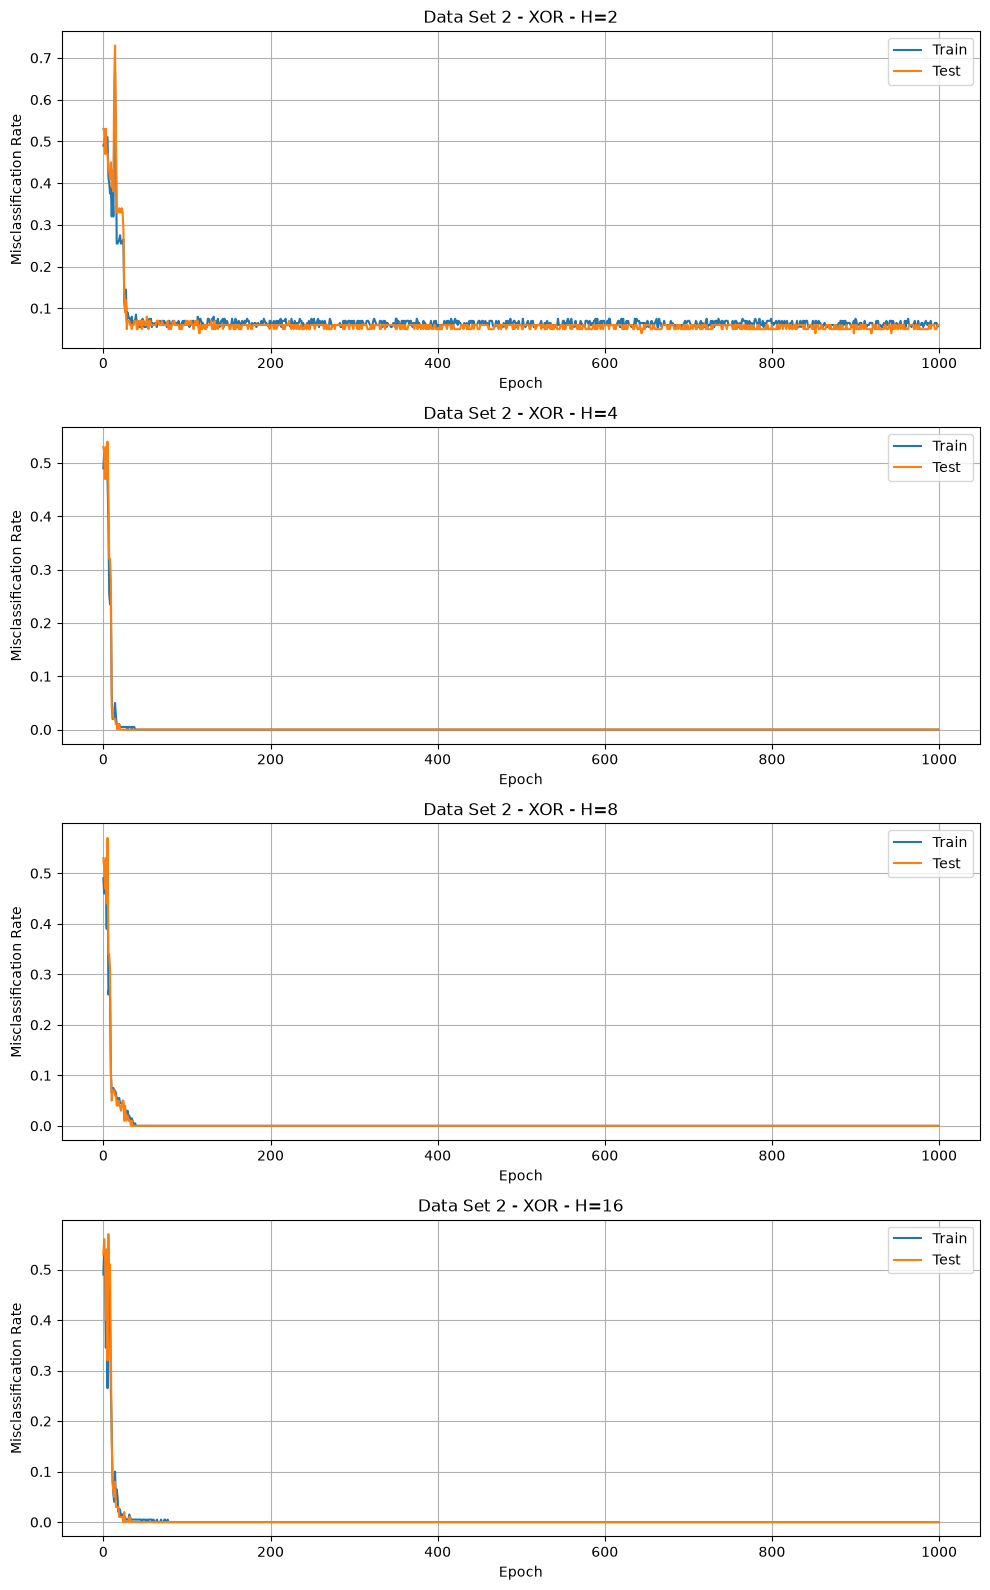

In [259]:
### 1 - Plot training and test miscs rates and give test confusion matrix - Joe
# we have 4 different h's show all on separate suplots, with confusion matrix,
fig,ax = plt.subplots(nrows=4, ncols=1, figsize=(10,16))
for i, H in enumerate(Hs):
    monitor = d2Hmonitors[i]

    print("Confusion Matrix for H = {}".format(H))
    print(confusion_matrix(d2yte, d2Hlabels[i]))
    ax[i].plot(monitor["miscs"], label="Train")
    ax[i].plot(monitor["testMiscs"], label="Test")

    ax[i].set_title(f"Data Set 2 - XOR - H={H}")
    ax[i].set_xlabel("Epoch")
    ax[i].set_ylabel("Misclassification Rate")
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

In [260]:
### 2 - Repeat H=2 with 5 different seeds and report 95%... - Joe
# collect statistics
d2Hlabels = []
seeds = [0,1,2,3,4]
for seed in seeds:
    W, monitor = mlp_train(d2Xtr,d2ytr,2,epochs=1000, seed=seed)
    
    # preds on test
    outputs,_ = forward(d2Xte,W)
    preds = np.where(outputs.ravel()>0.5,1,-1)

    # update
    d2Hlabels.append(preds)

In [261]:
### report runs with acc over 95%
num = 0
for i in range(5):
    acc = accuracy_score(d2yte, d2Hlabels[i])
    print(f"Run {i+1} acc: {acc}")
    if  acc>= 0.95:
        num+=1
print(" {} Runs out of 5 different seeds reached 95% test accuracy.".format(num))

Run 1 acc: 0.94
Run 2 acc: 0.94
Run 3 acc: 0.74
Run 4 acc: 0.93
Run 5 acc: 0.95
 1 Runs out of 5 different seeds reached 95% test accuracy.


# Overfitting and early stopping on data set 4 - Joe

In [262]:
### Data set 4 - iris_versicolor_virginica - Joe
dataDF = pd.read_csv("data/iris_versicolor_virginica.csv")

d4X = dataDF[["petal_length", "petal_width"]].values
d4y = dataDF["y"].values

# 60/20/20
d4Xtr, d4Xte, d4ytr, d4yte = stratified_split(d4X, d4y, test_fraction=1/5)
d4Xtr, d4Xval, d4ytr, d4yval = stratified_split(d4Xtr, d4ytr, test_fraction=1/4)

# standardize
d4mu = d4Xtr.mean(axis=0)
d4std = d4Xtr.std(axis=0)
d4std[d4std == 0] = 1

d4Xtr = (d4Xtr - d4mu) / d4std
d4Xval = (d4Xval - d4mu) / d4std
d4Xte = (d4Xte - d4mu) / d4std

print(len(d4Xtr), len(d4Xval), len(d4Xte))
d4W, d4monitor = mlp_train(d4Xtr, d4ytr, 16,epochs=3000, Xte=d4Xte, yte=d4yte, Xval=d4Xval, yval=d4yval)

60 20 20


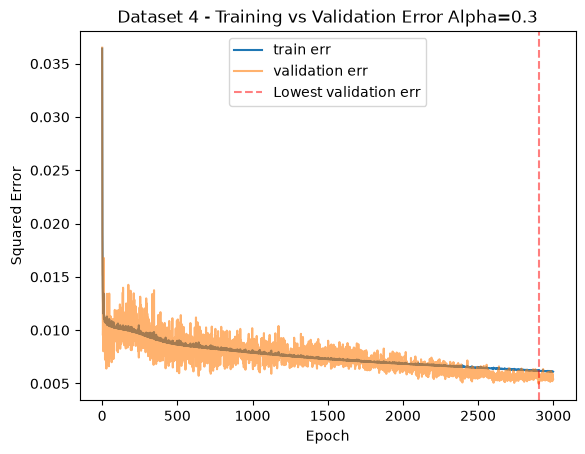

In [263]:
### 1 - Plot both curves, mark lowest val err - Joe
lowEpoch = np.argmin(d4monitor["valErrs"])
fig, ax = plt.subplots()
ax.plot(d4monitor["errs"],label="train err")
ax.plot(d4monitor["valErrs"], alpha=0.6,label="validation err")
ax.axvline(lowEpoch, color="red", linestyle="--", alpha=0.5, label="Lowest validation err")
plt.legend()
ax.set_xlabel("Epoch")
ax.set_ylabel("Squared Error")
ax.set_title("Dataset 4 - Training vs Validation Error Alpha=0.3")
plt.show()

In [264]:
### Data set 4 - iris_versicolor_virginica - optional with high alpha - Joe
dataDF = pd.read_csv("data/iris_versicolor_virginica.csv")

opd4X = dataDF[["petal_length", "petal_width"]].values
opd4y = dataDF["y"].values

# 60/20/20
opd4Xtr, opd4Xte, opd4ytr, opd4yte = stratified_split(opd4X, opd4y, test_fraction=1/5)
opd4Xtr, opd4Xval, opd4ytr, opd4yval = stratified_split(opd4Xtr, opd4ytr, test_fraction=1/4)

# standardize
opd4mu = opd4Xtr.mean(axis=0)
opd4std = opd4Xtr.std(axis=0)
opd4std[opd4std == 0] = 1

opd4Xtr = (opd4Xtr - opd4mu) / opd4std
opd4Xval = (opd4Xval - opd4mu) / opd4std
opd4Xte = (opd4Xte - opd4mu) / opd4std

print(len(opd4Xtr), len(opd4Xval), len(opd4Xte))
opd4W, opd4monitor = mlp_train(opd4Xtr, opd4ytr, 16,alpha=0.9,epochs=3000, Xte=opd4Xte, yte=opd4yte, Xval=opd4Xval, yval=opd4yval)

60 20 20


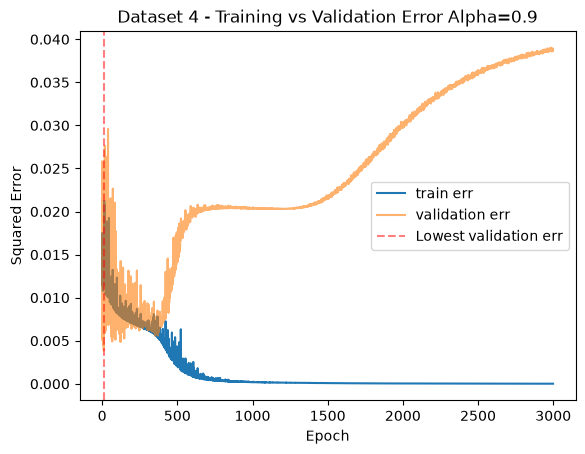

In [265]:
### 1 - Plot both curves, mark lowest val err - optional with high alpha - Joe
oplowEpoch = np.argmin(opd4monitor["valErrs"])
fig, ax = plt.subplots()
ax.plot(opd4monitor["errs"],label="train err")
ax.plot(opd4monitor["valErrs"], alpha=0.6,label="validation err")
ax.axvline(oplowEpoch, color="red", linestyle="--", alpha=0.5, label="Lowest validation err")
plt.legend()
ax.set_xlabel("Epoch")
ax.set_ylabel("Squared Error")
ax.set_title("Dataset 4 - Training vs Validation Error Alpha=0.9")
plt.show()

In [ ]:
### 2 - Report test acc and test confmat - Joe
lowEpochW = d4monitor["weights"][lowEpoch]
lowOutputs,_ = forward(d4Xte,lowEpochW)
lowPreds = np.where(lowOutputs.ravel()>0.5,1,-1)
outputs,_ = forward(d4Xte,d4W)
preds = np.where(outputs.ravel()>0.5,1,-1)

# test accs
print("Test Accuracy for the low epoch #{} : {:.4f}".format(lowEpoch, accuracy_score(d4yte,lowPreds)))
print("Test Accuracy for the final epoch: {:.4f}".format(accuracy_score(d4yte,preds)))

# confusion mats
print("Confusion Matrix for the low epoch #{}".format(lowEpoch+1))
print(confusion_matrix(d4yte, lowPreds))
print("Confusion Matrix for the final epoch")
print(confusion_matrix(d4yte, preds))

Test Accuracy for the low epoch #2903 : 0.9000
Test Accuracy for the final epoch: 0.9000
Confusion Matrix for the low epoch #2903
[[10  0]
 [ 2  8]]
Confusion Matrix for the final epoch
[[10  0]
 [ 2  8]]


### Problem 2 - Decision Surfaces: MLP vs. SMO

In [267]:
### Data set 1 - Iris,Setosa vs Versicolor - Joe
trainDF = pd.read_csv("data/iris_setosa_versicolor_train.csv")
testDF = pd.read_csv("data/iris_setosa_versicolor_test.csv")

# split into train and test, convert to numpy for mlp
Xtr = np.asarray(trainDF[["sepal_length","petal_length"]].values, dtype=float)
Xte = np.asarray(testDF[["sepal_length","petal_length"]].values, dtype=float)
ytr = np.asarray(trainDF["y"].values).ravel()
yte = np.asarray(testDF["y"].values).ravel()

In [268]:
### Data set 3 - RINGS - Joe
trainDF = pd.read_csv("data/rings_train.csv")
testDF = pd.read_csv("data/rings_test.csv")

# split into train and test
Xtr = trainDF[["x1","x2"]].values
Xte = testDF[["x1","x2"]].values
ytr = trainDF["y"].values
yte = testDF["y"].values